# DLinear: Decomposition + Linear Layers for Long-Term Forecasting

**Paper**: Ailing Zeng, Muxi Chen, Lei Zhang, Qiang Xu. *Are Transformers Effective for Time Series Forecasting?* AAAI 2023. [arXiv:2205.13504](https://arxiv.org/abs/2205.13504)

**Official code**: [github.com/cure-lab/LTSF-Linear](https://github.com/cure-lab/LTSF-Linear)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/dlinear_decomposition_linear.ipynb)

**Key ideas**:
- **The provocation**: a single linear layer mapping the look-back window directly to the whole horizon (*direct multi-step*, no autoregression) beat every Transformer of 2022 (Informer, Autoformer, FEDformer, ...) on the standard LTSF benchmarks.
- **Series decomposition** (borrowed from Autoformer): a moving average with kernel 25 splits the input into a smooth **trend** and a **seasonal/remainder** part.
- **Two linear layers**: one maps the seasonal part `L → H`, the other maps the trend part `L → H`; the forecast is their sum.
- **Channel-independent weights**: by default (`individual=False`) one pair of linear layers is *shared* across all channels; `individual=True` gives each channel its own pair.
- The whole model for ETTh1 96→96 has only **2 × (96·96 + 96) = 18,624 parameters**.

This notebook implements DLinear from scratch in PyTorch, faithfully to `models/DLinear.py` and the training recipe in `run_longExp.py` / `scripts/EXP-LongForecasting/Linear/etth1.sh`, and evaluates it on **ETTh1, multivariate (7 channels), horizon 96** with the standard Informer/Autoformer splits.

## Setup

DLinear only needs PyTorch, NumPy, pandas, scikit-learn and matplotlib, all of which are pre-installed on Colab, so there is nothing to `pip install`.

In [1]:
import os, time, json, random, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

torch 2.12.1+cu130 | device: cuda | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## Data: ETTh1 with the standard splits

ETTh1 is hourly electricity-transformer data (7 channels: 6 load features + oil temperature `OT`), July 2016 – June 2018.
We use the borders used by Informer / Autoformer / LTSF-Linear / TSLib:

| split | rows |
|---|---|
| train | `[0, 8640)` (12 months) |
| val | `[8640 − L, 11520)` (4 months) |
| test | `[11520 − L, 14400)` (4 months) |

The `StandardScaler` is fit on the train rows only and **metrics are computed in the scaled space**, which is what all LTSF papers report. Test windows slide with stride 1 → **2785 windows** for `L = 96, H = 96`.

In [2]:
import numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])


L, H = 96, 96          # look-back and horizon (paper-standard 96 -> 96)
train_arr, val_arr, test_arr, cols = load_etth1(L)
print("channels:", cols)
print("train/val/test rows:", train_arr.shape, val_arr.shape, test_arr.shape)
print("test windows:", len(WindowDataset(test_arr, L, H)))

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
train/val/test rows: (8640, 7) (2976, 7) (2976, 7)
test windows: 2785


## Component 1: moving-average series decomposition

For an input window $X \in \mathbb{R}^{L \times C}$ the trend is a centred moving average with kernel $k = 25$ (fixed in the official code). To keep the length at $L$, the series is padded by repeating its first and last value $(k-1)/2 = 12$ times:

$$X_t = \mathrm{AvgPool}_k\big(\mathrm{Pad}(X)\big), \qquad X_s = X - X_t .$$

`X_t` captures the slow level/trend, `X_s` the daily seasonality and noise. This is exactly the `moving_avg` / `series_decomp` block from Autoformer that DLinear reuses.

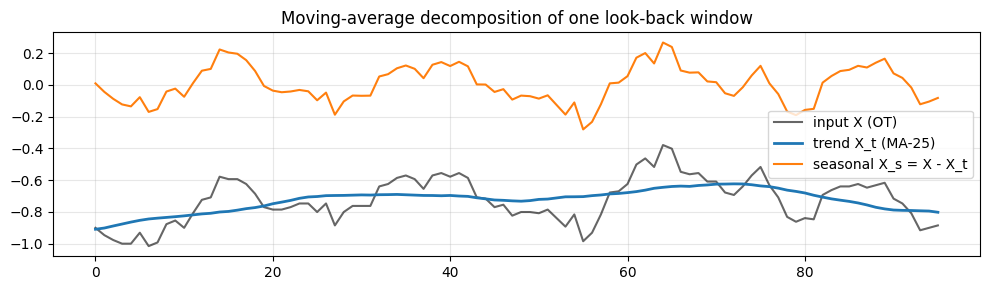

In [3]:
class MovingAvg(nn.Module):
    """Moving average with edge replication, so output length == input length."""
    def __init__(self, kernel_size, stride=1):
        super().__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)

    def forward(self, x):                      # x: [B, L, C]
        front = x[:, 0:1, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        end = x[:, -1:, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        x = torch.cat([front, x, end], dim=1)
        return self.avg(x.permute(0, 2, 1)).permute(0, 2, 1)


class SeriesDecomp(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()
        self.moving_avg = MovingAvg(kernel_size, stride=1)

    def forward(self, x):
        trend = self.moving_avg(x)
        return x - trend, trend               # (seasonal, trend)


# Visualise the decomposition on one test window (OT channel)
x0, _ = WindowDataset(test_arr, L, H)[0]
seas, trend = SeriesDecomp(25)(x0[None])
ot = cols.index("OT")
plt.figure(figsize=(10, 3))
plt.plot(x0[:, ot], label="input X (OT)", color="k", alpha=0.6)
plt.plot(trend[0, :, ot], label="trend X_t (MA-25)", lw=2)
plt.plot(seas[0, :, ot], label="seasonal X_s = X - X_t", lw=1.5)
plt.title("Moving-average decomposition of one look-back window"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Component 2: DLinear = one linear layer per component

Each component is mapped **along the time axis** from $L$ to $H$ by a single linear layer (applied identically to every channel when `individual=False`):

$$\hat{Y} = W_s X_s + b_s + W_t X_t + b_t, \qquad W_s, W_t \in \mathbb{R}^{H \times L}.$$

There is no normalisation, no embedding, no non-linearity. With `individual=True` every channel $c$ gets its own $(W_s^{(c)}, W_t^{(c)})$; the paper uses the shared version for ETTh1 (the script does not pass `--individual`), but the option is implemented below so you can try it (it tends to help on datasets whose channels behave very differently).

Weights use PyTorch's default `nn.Linear` initialisation, as in the official file (the `1/L` constant initialisation there is commented out and only meant for weight visualisation).

In [4]:
class DLinear(nn.Module):
    def __init__(self, seq_len, pred_len, enc_in, individual=False, kernel_size=25):
        super().__init__()
        self.seq_len, self.pred_len = seq_len, pred_len
        self.decomposition = SeriesDecomp(kernel_size)
        self.individual, self.channels = individual, enc_in
        if individual:
            self.Linear_Seasonal = nn.ModuleList([nn.Linear(seq_len, pred_len) for _ in range(enc_in)])
            self.Linear_Trend = nn.ModuleList([nn.Linear(seq_len, pred_len) for _ in range(enc_in)])
        else:
            self.Linear_Seasonal = nn.Linear(seq_len, pred_len)
            self.Linear_Trend = nn.Linear(seq_len, pred_len)

    def forward(self, x):                                  # x: [B, L, C]
        seasonal, trend = self.decomposition(x)
        seasonal, trend = seasonal.permute(0, 2, 1), trend.permute(0, 2, 1)   # [B, C, L]
        if self.individual:
            seasonal_out = torch.stack([self.Linear_Seasonal[i](seasonal[:, i]) for i in range(self.channels)], 1)
            trend_out = torch.stack([self.Linear_Trend[i](trend[:, i]) for i in range(self.channels)], 1)
        else:
            seasonal_out = self.Linear_Seasonal(seasonal)
            trend_out = self.Linear_Trend(trend)
        return (seasonal_out + trend_out).permute(0, 2, 1)  # [B, H, C]


m = DLinear(L, H, len(cols))
print("output shape:", m(torch.randn(4, L, len(cols))).shape)
print("params (individual=False):", sum(p.numel() for p in m.parameters()))
print("params (individual=True): ", sum(p.numel() for p in DLinear(L, H, len(cols), individual=True).parameters()))

output shape: torch.Size([4, 96, 7])
params (individual=False): 18624
params (individual=True):  130368


## Training recipe (from `run_longExp.py` + `etth1.sh`)

| setting | value |
|---|---|
| loss | MSE |
| optimizer | Adam, `lr = 0.005` (ETTh1 script) |
| batch size | 32, shuffled, `drop_last=True` |
| epochs | 10 max, early stopping on validation MSE with patience 3, best checkpoint restored |
| LR schedule | `type1`: halve the LR after every epoch, `lr_e = lr · 0.5^(e−1)` |

The evaluation function averages MSE and MAE over **all** windows, horizon steps and channels.

In [5]:
def make_loaders(train_arr, val_arr, test_arr, L, H, batch_size=32):
    g = torch.Generator().manual_seed(SEED)
    tr = torch.utils.data.DataLoader(WindowDataset(train_arr, L, H), batch_size=batch_size,
                                     shuffle=True, drop_last=True, generator=g)
    va = torch.utils.data.DataLoader(WindowDataset(val_arr, L, H), batch_size=256, shuffle=False)
    te = torch.utils.data.DataLoader(WindowDataset(test_arr, L, H), batch_size=256, shuffle=False)
    return tr, va, te


@torch.no_grad()
def evaluate(model, loader, return_preds=False):
    model.eval()
    se = ae = n = 0.0
    preds = []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        p = model(x)
        se += ((p - y) ** 2).sum().item(); ae += (p - y).abs().sum().item(); n += y.numel()
        if return_preds: preds.append(p.cpu())
    out = (se / n, ae / n)
    return out + (torch.cat(preds).numpy(),) if return_preds else out


def train_model(model, tr, va, te, lr, epochs=10, patience=3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    best, best_state, bad = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); losses = []
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward(); opt.step()
            losses.append(loss.item())
        v_mse, _ = evaluate(model, va); t_mse, _ = evaluate(model, te)
        print(f"epoch {ep:2d} | lr {opt.param_groups[0]['lr']:.2e} | train {np.mean(losses):.4f} "
              f"| val {v_mse:.4f} | test {t_mse:.4f} | {time.time()-t0:.1f}s")
        if v_mse < best:
            best, bad = v_mse, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
        for g in opt.param_groups:                       # lradj = type1
            g["lr"] = lr * 0.5 ** ep
    model.load_state_dict(best_state)
    return model

## Train DLinear on ETTh1 (L = 96 → H = 96)

In [6]:
seed_everything()
tr_loader, va_loader, te_loader = make_loaders(train_arr, val_arr, test_arr, L, H)
model = DLinear(L, H, len(cols), individual=False).to(device)
n_params = sum(p.numel() for p in model.parameters())
t_start = time.time()
model = train_model(model, tr_loader, va_loader, te_loader, lr=0.005)
train_seconds = time.time() - t_start
test_mse, test_mae, test_pred = evaluate(model, te_loader, return_preds=True)
print(f"\nDLinear L=96  | test MSE {test_mse:.4f} | test MAE {test_mae:.4f} | {n_params} params | {train_seconds:.1f}s")

epoch  1 | lr 5.00e-03 | train 0.3843 | val 0.6688 | test 0.4029 | 0.9s


epoch  2 | lr 2.50e-03 | train 0.3544 | val 0.6695 | test 0.3953 | 0.7s


epoch  3 | lr 1.25e-03 | train 0.3506 | val 0.6647 | test 0.3822 | 0.8s


epoch  4 | lr 6.25e-04 | train 0.3485 | val 0.6668 | test 0.3830 | 0.8s


epoch  5 | lr 3.13e-04 | train 0.3473 | val 0.6583 | test 0.3832 | 0.8s


epoch  6 | lr 1.56e-04 | train 0.3466 | val 0.6656 | test 0.3815 | 0.8s


epoch  7 | lr 7.81e-05 | train 0.3463 | val 0.6599 | test 0.3819 | 0.8s


epoch  8 | lr 3.91e-05 | train 0.3462 | val 0.6591 | test 0.3818 | 0.7s
early stopping

DLinear L=96  | test MSE 0.3832 | test MAE 0.3955 | 18624 params | 6.7s


## Bonus: the paper's own setting (L = 336)

The DLinear paper's main table uses a longer look-back, `L = 336`, because linear models keep improving with longer inputs (Transformers usually do not, which is one of the paper's points). The splits shift accordingly (val/test start `L` rows earlier), and the number of test windows stays 2785. Training takes a few seconds, so we run it too.

In [7]:
L2 = 336
seed_everything()
tr2, va2, te2_arr, _ = load_etth1(L2)
tl2, vl2, el2 = make_loaders(tr2, va2, te2_arr, L2, H)
model336 = train_model(DLinear(L2, H, len(cols)).to(device), tl2, vl2, el2, lr=0.005)
mse336, mae336 = evaluate(model336, el2)
print(f"\nDLinear L=336 | test MSE {mse336:.4f} | test MAE {mae336:.4f} | test windows {len(el2.dataset)}")

epoch  1 | lr 5.00e-03 | train 0.4015 | val 0.7489 | test 0.4168 | 0.8s


epoch  2 | lr 2.50e-03 | train 0.3539 | val 0.7058 | test 0.3945 | 0.8s


epoch  3 | lr 1.25e-03 | train 0.3442 | val 0.6587 | test 0.3816 | 0.8s


epoch  4 | lr 6.25e-04 | train 0.3374 | val 0.6633 | test 0.3745 | 0.8s


epoch  5 | lr 3.13e-04 | train 0.3345 | val 0.6699 | test 0.3724 | 0.8s


epoch  6 | lr 1.56e-04 | train 0.3324 | val 0.6487 | test 0.3738 | 0.8s


epoch  7 | lr 7.81e-05 | train 0.3313 | val 0.6593 | test 0.3702 | 0.8s


epoch  8 | lr 3.91e-05 | train 0.3307 | val 0.6557 | test 0.3704 | 0.8s


epoch  9 | lr 1.95e-05 | train 0.3306 | val 0.6536 | test 0.3703 | 0.8s
early stopping

DLinear L=336 | test MSE 0.3738 | test MAE 0.3951 | test windows 2785


## Forecast plot (OT channel)

History (look-back), ground truth and DLinear forecast for a few test windows, in the scaled space.

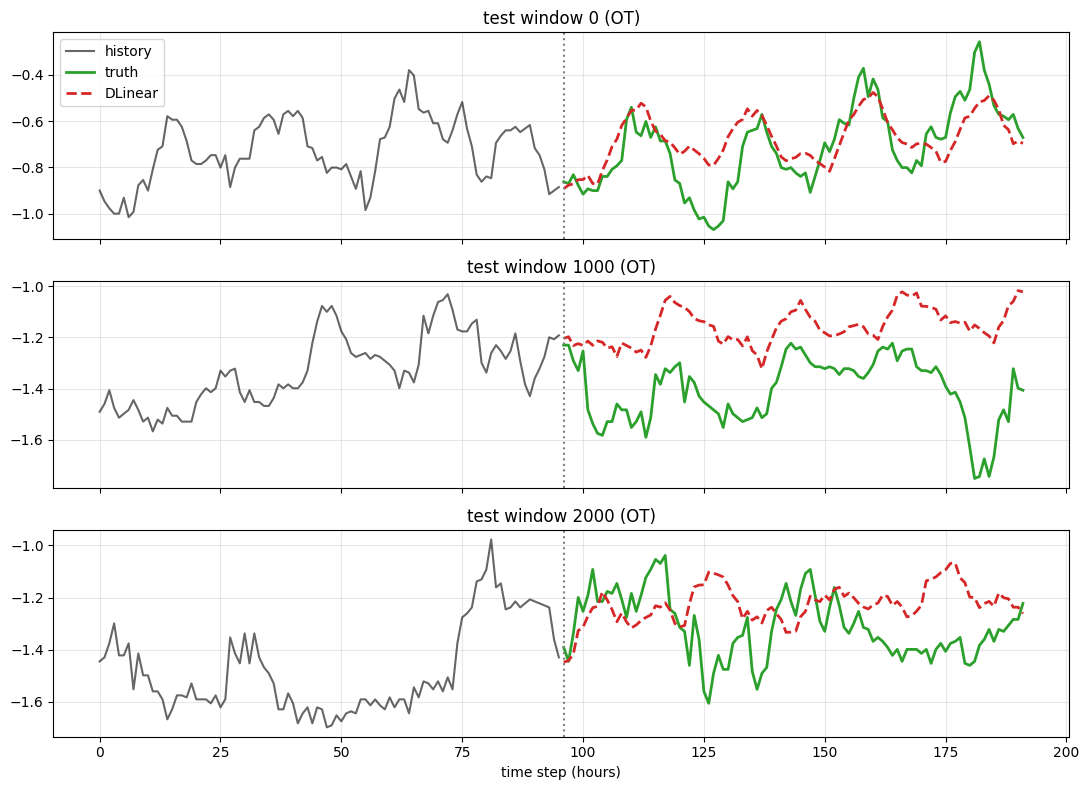

In [8]:
te_ds = WindowDataset(test_arr, L, H)
ot = cols.index("OT")
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, k in zip(axes, [0, 1000, 2000]):
    x, y = te_ds[k]
    ax.plot(np.arange(L), x[:, ot], color="k", alpha=0.6, label="history")
    ax.plot(np.arange(L, L + H), y[:, ot], color="tab:green", lw=2, label="truth")
    ax.plot(np.arange(L, L + H), test_pred[k, :, ot], "--", color="tab:red", lw=2, label="DLinear")
    ax.axvline(L, color="gray", ls=":"); ax.set_title(f"test window {k} (OT)"); ax.grid(alpha=0.3)
axes[0].legend(loc="upper left"); axes[-1].set_xlabel("time step (hours)")
plt.tight_layout(); plt.show()

## What did the linear layers learn?

Because the model is linear, the weights are directly interpretable (Fig. 6 of the paper). Each row is one forecast step, each column one input step. Periodic stripes in the seasonal weights reflect the daily (24-step) cycle that the model exploits.

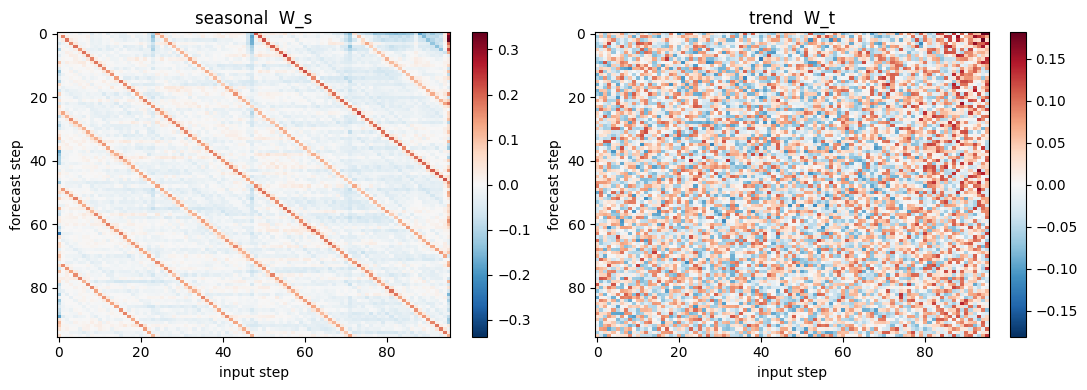

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, lin) in zip(axes, [("seasonal  W_s", model.Linear_Seasonal), ("trend  W_t", model.Linear_Trend)]):
    w = lin.weight.detach().cpu().numpy()
    im = ax.imshow(w, cmap="RdBu_r", vmin=-np.abs(w).max(), vmax=np.abs(w).max(), aspect="auto")
    ax.set_title(name); ax.set_xlabel("input step"); ax.set_ylabel("forecast step")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## Results

Reference numbers for ETTh1 96→96 (multivariate, scaled):
- **L = 96**: DLinear 0.386 / 0.400 (MSE / MAE), as reported for DLinear with `L = 96` in the iTransformer paper (ICLR 2024) and TSLib.
- **L = 336**: DLinear paper (AAAI 2023, Table 2) reports 0.375 / 0.399.

In [10]:
PAPER = {96: (0.386, 0.400), 336: (0.375, 0.399)}
print(f"{'setting':<22}{'MSE':>8}{'MAE':>8}   {'paper MSE':>10}{'paper MAE':>10}")
print(f"{'DLinear L=96  (ours)':<22}{test_mse:8.4f}{test_mae:8.4f}   {PAPER[96][0]:10.3f}{PAPER[96][1]:10.3f}")
print(f"{'DLinear L=336 (ours)':<22}{mse336:8.4f}{mae336:8.4f}   {PAPER[336][0]:10.3f}{PAPER[336][1]:10.3f}")
print(f"\nparams: {n_params} | train time (L=96): {train_seconds:.1f} s | device: {device}")

results = {
    "model": "DLinear",
    "paper": "Are Transformers Effective for Time Series Forecasting? (Zeng et al.)",
    "venue": "AAAI 2023",
    "type": "supervised",
    "lookback": L, "horizon": H,
    "mse": round(test_mse, 4), "mae": round(test_mae, 4),
    "paper_mse": PAPER[96][0], "paper_mae": PAPER[96][1],
    "params": n_params,
    "train_or_infer_seconds": round(train_seconds, 1),
    "notes": (f"From-scratch DLinear (individual=False, MA kernel 25), Adam lr 0.005, bs 32, MSE loss, "
              f"10 epochs max, patience 3, lr halved each epoch (official etth1.sh / run_longExp.py). "
              f"Test: all 2785 stride-1 windows. paper_mse/mae for L=96 are the iTransformer-paper/TSLib DLinear numbers; "
              f"extra run with the DLinear paper's L=336: mse {mse336:.4f}, mae {mae336:.4f} (paper 0.375/0.399)."),
    "extra": {"lookback_336": {"mse": round(mse336, 4), "mae": round(mae336, 4), "paper_mse": 0.375, "paper_mae": 0.399}},
}
try:
    with open("results_dlinear_decomposition_linear.json", "w") as f:
        json.dump(results, f, indent=2)
    print("wrote results_dlinear_decomposition_linear.json")
except Exception as e:
    print("could not write results JSON:", e)

setting                    MSE     MAE    paper MSE paper MAE
DLinear L=96  (ours)    0.3832  0.3955        0.386     0.400
DLinear L=336 (ours)    0.3738  0.3951        0.375     0.399

params: 18624 | train time (L=96): 6.7 s | device: cuda
wrote results_dlinear_decomposition_linear.json


## Using your own data

1. Load any `(T, C)` float array, split it chronologically, fit a `StandardScaler` on the training part only, and build `WindowDataset`s with your own `L` and `H`:
   ```python
   df = pd.read_csv("my_series.csv", parse_dates=["date"])
   data = df.drop(columns=["date"]).values.astype(np.float32)
   n_tr, n_va = int(0.7 * len(data)), int(0.1 * len(data))
   scaler = StandardScaler().fit(data[:n_tr]); data = scaler.transform(data).astype(np.float32)
   train_arr, val_arr, test_arr = data[:n_tr], data[n_tr - L:n_tr + n_va], data[n_tr + n_va - L:]
   ```
2. Instantiate `DLinear(seq_len=L, pred_len=H, enc_in=C, individual=False)` and call `train_model`.
3. Tips:
   - **Longer look-back usually helps** linear models (try `L = 336` or `512` for hourly data).
   - Use `individual=True` when channels have very different dynamics (e.g. mixed sensors); keep `False` for many similar channels.
   - The MA `kernel_size=25` is a good default for hourly data; pick roughly one period for other resolutions.
   - Invert the scaling with `scaler.inverse_transform` to get forecasts in original units.